## Part A — Dataset and graph construction 

In [1]:
# ============================================================
# SECTION 0 — Imports and reproducibility
# ============================================================
import os
import random
import warnings
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm # matplotlib's colormap functionality
import seaborn as sns
import networkx as nx
import igraph as ig
import community as community_louvain #tentative community detection 
from scipy.stats import spearmanr # spearmanrank correlation

warnings.filterwarnings("ignore")

# reproducibility
GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

# output folder
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

In [2]:
# ============================================================
# SECTION 1 — Load polblogs.gml
# ============================================================
GML_PATH = "polblogs.gml"

def load_graph(path=GML_PATH):
    """
    Load polblogs.gml.
    The raw file contains duplicate edges, so NetworkX's default simple-graph
    reader raises. We route through igraph, which silently collapses duplicates,
    and rebuild a NetworkX DiGraph with all node attributes preserved.
    """
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing {path}. Download polblogs.zip from "
            "https://public.websites.umich.edu/~mejn/netdata/ and unzip here."
        )
    try:
        return nx.read_gml(path, label="id")
    except nx.NetworkXError:
        # Duplicate edges: route through igraph
        g_ig = ig.Graph.Read_GML(path)
        g = nx.DiGraph()
        for v in g_ig.vs:
            attrs = {k: v[k] for k in v.attributes() if v[k] is not None}
            node_id = int(attrs.get("id", v.index))
            g.add_node(node_id, **attrs)
        for e in g_ig.es:
            s = int(g_ig.vs[e.source]["id"])
            t = int(g_ig.vs[e.target]["id"])
            g.add_edge(s, t)
        return g

G_raw = load_graph()

print("=== RAW GRAPH ===")
print(f"Nodes    : {G_raw.number_of_nodes()}")
print(f"Edges    : {G_raw.number_of_edges()}")
print(f"Directed : {G_raw.is_directed()}")
print(f"Sample node attrs: {list(G_raw.nodes(data=True))[0]}")

=== RAW GRAPH ===
Nodes    : 1490
Edges    : 19025
Directed : True
Sample node attrs: (1, {'id': 1.0, 'label': '100monkeystyping.com', 'value': 0.0, 'source': 'Blogarama'})


In [3]:
# ============================================================
# SECTION 2 — Preprocessing
# ============================================================
def preprocess(g):
    """
    Clean the raw graph and return (clean_graph, labels, log).
    Decisions:
      1. Cast id and value to int (they load as float from GML).
      2. Remove self-loops (a blog linking to itself carries no relational info).
      3. Collapse duplicate edges (already done at load time via igraph).
      4. Keep isolates — they are real labelled blogs needed for evaluation.
    """
    log = []
    g = g.copy()

    # 1) Cast node ids and 'value' to int
    mapping = {n: int(n) for n in g.nodes()}
    g = nx.relabel_nodes(g, mapping)
    for n in g.nodes():
        g.nodes[n]["value"] = int(g.nodes[n]["value"])
        g.nodes[n]["id"] = int(g.nodes[n]["id"])

    # Labels preserved separately (ground truth — used only in Part E)
    labels = {n: g.nodes[n]["value"] for n in g.nodes()}

    # 2) Remove self-loops
    before_e = g.number_of_edges()
    self_loops = list(nx.selfloop_edges(g))
    g.remove_edges_from(self_loops)
    log.append(("Remove self-loops", before_e, g.number_of_edges(), len(self_loops)))

    # 3) Duplicate edges: already collapsed at load time
    log.append(("Collapse duplicate edges (at load via igraph)",
                g.number_of_edges(), g.number_of_edges(), 0))

    # 4) Isolates — detect but keep
    isolates = list(nx.isolates(g))
    log.append(("Isolates detected (kept)", len(isolates), len(isolates), len(isolates)))

    return g, labels, log, isolates


G, LABELS, PREP_LOG, ISOLATES = preprocess(G_raw)

df_log = pd.DataFrame(
    PREP_LOG,
    columns=["Step", "Before", "After", "Removed/Detected"]
)
print("=== PREPROCESSING LOG ===")
display(df_log)
print(f"\nFinal analysis graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

=== PREPROCESSING LOG ===


,Step,Before,After,Removed/Detected
0,Remove self-loops,19025,19022,3
1,Collapse duplicate edges (at load via igraph),19022,19022,0
2,Isolates detected (kept),266,266,266



Final analysis graph: 1490 nodes, 19022 edges


### Data dictionary

| Element | Meaning |
|---|---|
| **Node** | A political blog (weblog) |
| **Node `id`** | Unique integer identifier for the blog |
| **Node `label`** | Blog name / domain |
| **Node `value`** | Binary political orientation — **0 = liberal, 1 = conservative**. Ground truth; used ONLY in Part E evaluation. |
| **Node `source`** | Directory where the blog was listed (e.g., Blogarama) — auxiliary attribute, not used in analysis |
| **Edge** | A hyperlink from one blog to another |
| **Edge direction** | `source → target` means source blog links to target blog |
| **Edge weight** | None — unweighted |
| **Multi-edge** | No — duplicate edges collapsed at load time |
| **Self-loop** | No — removed during preprocessing |

### Graph model

- **Directed** — hyperlinks have a meaningful direction (who links to whom).
- **Unweighted** — a link is either present or absent; there is no strength value.
- **Simple** — at most one edge per ordered pair (duplicate edges collapsed).

In [4]:
# ============================================================
# SECTION 3 — Graph properties
# ============================================================
def graph_properties(g):
    n = g.number_of_nodes()
    m = g.number_of_edges()
    density = nx.density(g)

    wcc = list(nx.weakly_connected_components(g))
    scc = list(nx.strongly_connected_components(g))
    largest_wcc = max(wcc, key=len)

    props = {
        "Nodes": n,
        "Edges": m,
        "Density": round(density, 6),
        "# Weakly connected components (WCC)": len(wcc),
        "Largest WCC size": len(largest_wcc),
        "# Strongly connected components (SCC)": len(scc),
        "Largest SCC size": max(len(c) for c in scc),
    }
    return props, largest_wcc, wcc, scc


PROPS, LARGEST_WCC, WCC, SCC = graph_properties(G)

print("=== GRAPH PROPERTIES ===")
for k, v in PROPS.items():
    print(f"{k:40s}: {v}")

# Analysis subgraph: largest weakly connected component
G_WCC = G.subgraph(LARGEST_WCC).copy()
print(f"\nLargest WCC subgraph: {G_WCC.number_of_nodes()} nodes, {G_WCC.number_of_edges()} edges")

=== GRAPH PROPERTIES ===
Nodes                                   : 1490
Edges                                   : 19022
Density                                 : 0.008574
# Weakly connected components (WCC)     : 268
Largest WCC size                        : 1222
# Strongly connected components (SCC)   : 688
Largest SCC size                        : 793

Largest WCC subgraph: 1222 nodes, 19021 edges


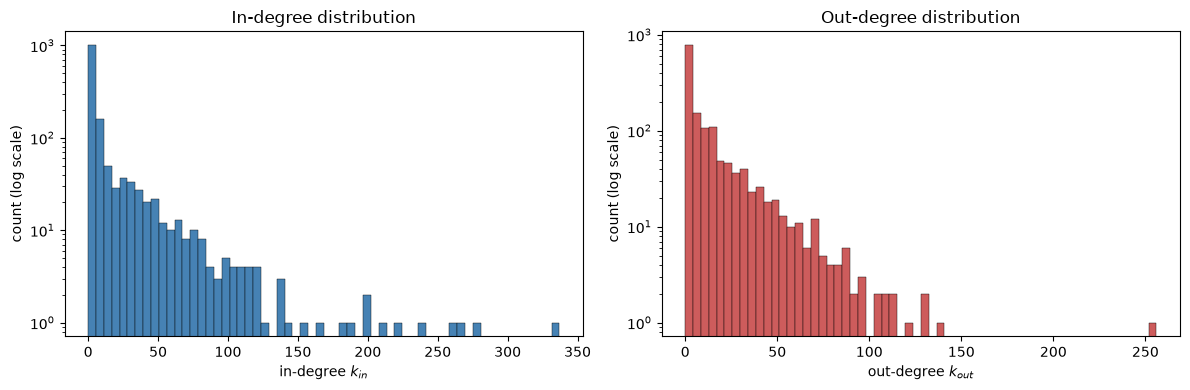

In-degree : mean=12.77, median=2.0, max=337
Out-degree: mean=12.77, median=4.0, max=256


In [5]:
# ============================================================
# SECTION 3b — Degree distribution figure
# ============================================================
in_deg  = [d for _, d in G.in_degree()]
out_deg = [d for _, d in G.out_degree()]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(in_deg, bins=60, color="steelblue", edgecolor="black", linewidth=0.3)
axes[0].set_title("In-degree distribution")
axes[0].set_xlabel("in-degree $k_{in}$")
axes[0].set_ylabel("count (log scale)")
axes[0].set_yscale("log")

axes[1].hist(out_deg, bins=60, color="indianred", edgecolor="black", linewidth=0.3)
axes[1].set_title("Out-degree distribution")
axes[1].set_xlabel("out-degree $k_{out}$")
axes[1].set_ylabel("count (log scale)")
axes[1].set_yscale("log")

plt.tight_layout()
plt.savefig(f"{OUT}/fig_degree_distribution.png", bbox_inches="tight")
plt.show()

print(f"In-degree : mean={np.mean(in_deg):.2f}, median={np.median(in_deg)}, max={max(in_deg)}")
print(f"Out-degree: mean={np.mean(out_deg):.2f}, median={np.median(out_deg)}, max={max(out_deg)}")

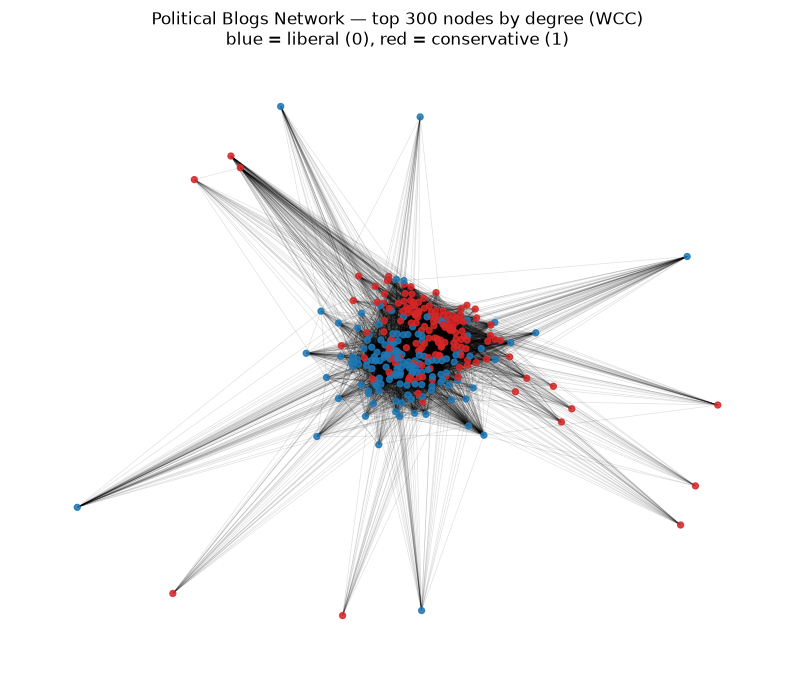

In [6]:
# ============================================================
# SECTION 3c — Readable network visualization (top-300 by degree)
# ============================================================
def visualize_top_nodes(g, top_k=300, labels=None, seed=GLOBAL_SEED,
                        fname="fig_network.png"):
    """Visualize the top-K nodes by total degree in the largest WCC."""
    wcc = max(nx.weakly_connected_components(g), key=len)
    sub = g.subgraph(wcc).copy()

    top_nodes = [n for n, _ in sorted(sub.degree, key=lambda x: x[1], reverse=True)[:top_k]]
    sub = sub.subgraph(top_nodes).copy()

    pos = nx.spring_layout(sub, seed=seed, k=0.15)
    colors = ["#1f77b4" if labels[n] == 0 else "#d62728" for n in sub.nodes()]

    plt.figure(figsize=(10, 8))
    nx.draw_networkx_nodes(sub, pos, node_color=colors, node_size=18, alpha=0.85)
    nx.draw_networkx_edges(sub, pos, alpha=0.12, arrows=False, width=0.5)
    plt.title(f"Political Blogs Network — top {top_k} nodes by degree (WCC)\n"
              "blue = liberal (0), red = conservative (1)")
    plt.axis("off")
    plt.savefig(f"{OUT}/{fname}", bbox_inches="tight")
    plt.show()


visualize_top_nodes(G, top_k=300, labels=LABELS)

### Part A — Interpretation

- The graph is **sparse** (density ≈ 0.0086), meaning that most blogs do not link directly to most other blogs.

- The in-degree and out-degree distributions are **strongly right-skewed with long tails**. The median in-degree is 2 and the median out-degree is 4, while the maximum in-degree and out-degree are 337 and 256, respectively. This indicates that most blogs have relatively few links, while a small number of highly connected blogs act as network hubs.

- The graph has **one dominant weakly connected component but is globally disconnected**. The largest weakly connected component (WCC) contains 1,222 of the 1,490 nodes (82%), while there are 268 WCCs in total. Thus, most blogs belong to one large connected network when edge direction is ignored, while the remaining nodes occur in smaller disconnected components.

- The directed structure is more fragmented in terms of mutual reachability. There are 688 strongly connected components (SCCs), and the largest SCC contains 793 nodes (53% of all nodes). This indicates that many blogs cannot mutually reach one another while respecting the direction of hyperlinks, which is relevant to understanding information flow through the network.

- The mean in-degree and mean out-degree are both **12.77**. This equality is expected in a directed graph because every directed edge contributes one unit to the out-degree of its source and one unit to the in-degree of its target.

- The label-colored network visualization provides an **exploratory view** of the relationship between political orientation and network structure. Some apparent clustering of the two orientations can be observed. However, the political-orientation labels are **not used to construct, seed, tune, or select communities**. They are preserved only for evaluation of the communities detected from the network structure.

- Because the graph is disconnected, **distance-based calculations require a clearly stated component and edge-direction convention**. For subsequent distance-based analysis, the largest WCC containing 1,222 nodes will be used, with the direction convention explicitly stated for each distance-based measure.

## Part B — Centrality Selection and Analysis

### Chosen centralities

**1. PageRank**

*Question:* Which blogs are most authoritative in the directed hyperlink
network, where influence received is diluted across each source's outgoing links?

*Why PageRank over alternatives:*
- Better than **in-degree** because it weighs links by the source's own authority
  (a link from a hub counts more than a link from a leaf).
- Better than **Katz** because PageRank is designed for directed graphs with
  highly skewed outgoing degrees and handles dangling nodes robustly via the
  damping factor.
- Better than **eigenvector centrality** because PageRank is well-defined on
  directed graphs even when the adjacency matrix is not irreducible.

**2. Betweenness centrality**

*Question:* Which blogs act as brokers or bridges between otherwise separated
regions of the network?

*Why betweenness over alternatives:*
- Directly operationalises brokerage: it counts how often a node lies on
  shortest paths between other pairs.
- **Closeness** measures reachability, not brokerage.
- **Eigenvector / Katz** measure importance by association, not by bridging.
- **PageRank** measures authority, not cross-community connection.

### Direction and component conventions

| Measure | Direction | Component | Justification |
|---|---|---|---|
| PageRank | Uses **incoming** links | Whole graph | Well-defined even on disconnected graphs |
| Betweenness | **Undirected** interpretation | **Largest WCC** (1222 nodes) | Distances are undefined across components; a hyperlink between two blogs is navigable in both directions in practice |

### Parameters

- **PageRank:** damping `α = 0.85`, tolerance `1e-6`, max iterations 100.
- **Betweenness:** normalized = True, unweighted.

Unreachable pairs contribute 0 to betweenness, which is the standard
NetworkX convention.

### Formulas

**PageRank.**
For node $v$ with $N$ nodes total and damping factor $\alpha$:

$$PR(v) = \frac{1 - \alpha}{N} + \alpha \sum_{u \in \text{In}(v)} \frac{PR(u)}{L(u)}$$

where $\text{In}(v)$ is the set of nodes with an edge into $v$, and $L(u)$
is the out-degree of $u$. Dangling nodes (out-degree 0) have their mass
redistributed uniformly across all nodes.

**Betweenness centrality.**
For node $v$:

$$BC(v) = \sum_{s \neq v \neq t} \frac{\sigma_{st}(v)}{\sigma_{st}}$$

where $\sigma_{st}$ is the number of shortest paths from $s$ to $t$,
and $\sigma_{st}(v)$ is the number of those paths passing through $v$.

### Normalization

- **PageRank** is naturally normalized: $\sum_v PR(v) = 1$. No additional
  normalization is applied — this is the standard convention [Brin & Page 1998].
- **Betweenness** is normalized by dividing by the number of possible
  unordered node pairs (excluding $v$): `normalized=True` in NetworkX.

### Parameter justification

- **$\alpha = 0.85$** is the standard PageRank value from [Brin & Page 1998].
  It balances the two components: with probability 0.85 the random surfer
  follows a link, with probability 0.15 they jump to a random node. Lower
  α (e.g. 0.5) makes the score closer to uniform; higher α (e.g. 0.95)
  makes it too sensitive to long link chains and can slow convergence.
  0.85 is the accepted convention across the literature.
- **tol = 1e-6** and **max_iter = 100** are convergence thresholds. PageRank
  is iterative (power iteration); we stop when the L1 change between
  iterations drops below tol or we reach max_iter.

### Convergence handling

Run the convergence-check cell below to report the actual number of
iterations until convergence.

In [13]:
# ============================================================
# SECTION 4a — PageRank
# ============================================================
def compute_pagerank(g, alpha=0.85, tol=1e-6, max_iter=100):
    """
    PageRank with damping factor alpha.
    Uses incoming links (authority = links received).
    Dangling nodes handled by NetworkX by redistributing mass uniformly.
    """
    return nx.pagerank(g, alpha=alpha, tol=tol, max_iter=max_iter)


PAGERANK = compute_pagerank(G, alpha=0.85, tol=1e-6, max_iter=100)
pr_series = pd.Series(PAGERANK).sort_values(ascending=False)


def topk_table(series, g, labels, k=10, value_name="score", normalize=False):
    """
    Top-K table.
    If normalize=True, adds a 'Normalized' column (score / sum of all scores).
    """
    top = series.head(k)
    df = pd.DataFrame({
        "Rank": range(1, k + 1),
        "Node ID": top.index.astype(int),
        "Label": [g.nodes[n].get("label", str(n)) for n in top.index],
        f"{value_name} (raw)": top.values.round(6),
        "Political label": [labels[n] for n in top.index],
    })
    if normalize:
        df[f"{value_name} (normalized)"] = (top / series.sum()).values.round(6)
    return df


top10_pr = topk_table(pr_series, G, LABELS, k=10, value_name="PageRank",
                      normalize=True)
print("=== TOP-10 BY PAGERANK ===")
display(top10_pr)

=== TOP-10 BY PAGERANK ===


,Rank,Node ID,Label,PageRank (raw),Political label,PageRank (normalized)
0,1,155,dailykos.com,0.017937,0,0.017937
1,2,55,atrios.blogspot.com,0.015209,0,0.015209
2,3,1051,instapundit.com,0.012652,1,0.012652
3,4,855,blogsforbush.com,0.012534,1,0.012534
4,5,641,talkingpointsmemo.com,0.012418,0,0.012418
5,6,1153,michellemalkin.com,0.010940,1,0.010940
6,7,963,drudgereport.com,0.010735,1,0.010735
7,8,729,washingtonmonthly.com,0.010532,0,0.010532
8,9,1245,powerlineblog.com,0.008957,1,0.008957
9,10,798,andrewsullivan.com,0.008625,1,0.008625


PageRank converged in 49 iterations (tol = 1e-6)


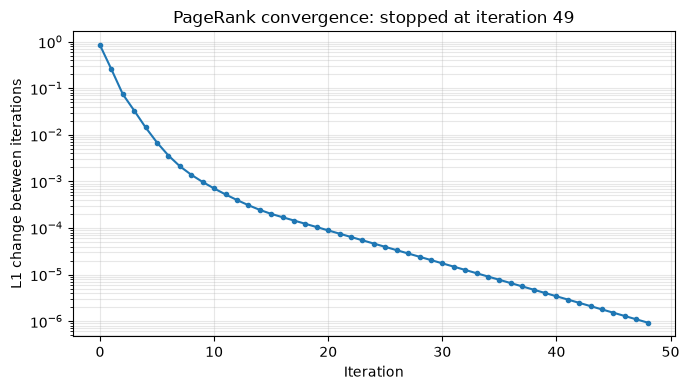

In [14]:
# ============================================================
# SECTION 4a-2 — PageRank convergence check
# ============================================================
pagerank_history = []

def pagerank_with_tracking(g, alpha=0.85, tol=1e-6, max_iter=100):
    """Run PageRank and record the L1 norm of change per iteration."""
    import numpy as np
    n = g.number_of_nodes()
    nodes = list(g.nodes())
    idx = {n: i for i, n in enumerate(nodes)}

    # Build transition matrix
    A = np.zeros((n, n))
    for u, v in g.edges():
        A[idx[v], idx[u]] += 1.0           # column-stochastic (in-links)
    out_deg = A.sum(axis=0)
    dangling = out_deg == 0
    for j in range(n):
        if out_deg[j] > 0:
            A[:, j] /= out_deg[j]
        else:
            A[:, j] = 1.0 / n               # dangling redistribution

    pr = np.ones(n) / n
    history = []
    for it in range(max_iter):
        pr_new = (1 - alpha) / n + alpha * (A @ pr)
        diff = np.abs(pr_new - pr).sum()
        history.append(diff)
        pr = pr_new
        if diff < tol:
            break

    return {nodes[i]: pr[i] for i in range(n)}, it + 1, history


_, ITERS, PR_HISTORY = pagerank_with_tracking(G, alpha=0.85, tol=1e-6)
print(f"PageRank converged in {ITERS} iterations (tol = 1e-6)")

plt.figure(figsize=(7, 4))
plt.plot(PR_HISTORY, marker="o", markersize=3)
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("L1 change between iterations")
plt.title(f"PageRank convergence: stopped at iteration {ITERS}")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT}/fig_pagerank_convergence.png", bbox_inches="tight")
plt.show()

In [15]:
# ============================================================
# SECTION 4b — Betweenness centrality (largest WCC, undirected interpretation)
# ============================================================
BETWEENNESS = nx.betweenness_centrality(G_WCC, normalized=True, weight=None)
bc_series = pd.Series(BETWEENNESS).sort_values(ascending=False)

top10_bc = topk_table(bc_series, G, LABELS, k=10, value_name="Betweenness",normalize=True)
print("=== TOP-10 BY BETWEENNESS (largest WCC) ===")
display(top10_bc)

=== TOP-10 BY BETWEENNESS (largest WCC) ===


,Rank,Node ID,Label,Betweenness (raw),Political label,Betweenness (normalized)
0,1,855,blogsforbush.com,0.146658,1,0.093147
1,2,55,atrios.blogspot.com,0.061080,0,0.038794
2,3,1051,instapundit.com,0.051201,1,0.032519
3,4,155,dailykos.com,0.036910,0,0.023443
4,5,454,newleftblogs.blogspot.com,0.030810,0,0.019569
5,6,387,madkane.com/notable.html,0.030224,0,0.019196
6,7,1479,wizbangblog.com,0.027257,1,0.017312
7,8,1101,lashawnbarber.com,0.024258,1,0.015407
8,9,1041,hughhewitt.com,0.022992,1,0.014603
9,10,729,washingtonmonthly.com,0.021925,0,0.013925


In [16]:
# ============================================================
# SECTION 4c — Compare PageRank vs Betweenness rankings
# ============================================================
from scipy.stats import spearmanr

# Top-10 overlap
pr_top = set(pr_series.head(10).index)
bc_top = set(bc_series.head(10).index)
overlap = pr_top & bc_top

print(f"Top-10 overlap: {len(overlap)} nodes")
for n in sorted(overlap):
    print(f"  Node {n} ({G.nodes[n].get('label','?')})")

# Spearman rank correlation over all nodes present in both dicts
common = [n for n in G_WCC.nodes() if n in PAGERANK and n in BETWEENNESS]
rho, pval = spearmanr(
    [PAGERANK[n] for n in common],
    [BETWEENNESS[n] for n in common]
)
print(f"\nSpearman rho = {rho:.3f}  (p-value = {pval:.2e}, n = {len(common)})")

Top-10 overlap: 5 nodes
  Node 55 (atrios.blogspot.com)
  Node 155 (dailykos.com)
  Node 729 (washingtonmonthly.com)
  Node 855 (blogsforbush.com)
  Node 1051 (instapundit.com)

Spearman rho = 0.758  (p-value = 2.98e-228, n = 1222)


In [17]:
# ============================================================
# SECTION 4d — Interpret the top nodes in network terms
# ============================================================
def describe_node(n):
    return {
        "Node ID": int(n),
        "Label": G.nodes[n].get("label", "?"),
        "Political label (0=lib,1=con)": LABELS[n],
        "In-degree": G.in_degree(n),
        "Out-degree": G.out_degree(n),
        "PageRank": round(PAGERANK[n], 6),
        "Betweenness": round(BETWEENNESS.get(n, 0.0), 6),
    }

# Pick 3+ nodes: top PageRank, top Betweenness, and one strong cross-over if present
candidates = list(dict.fromkeys(
    list(pr_series.head(3).index) +
    list(bc_series.head(3).index)
))[:6]

interp_df = pd.DataFrame([describe_node(n) for n in candidates])
print("=== NODE-LEVEL INTERPRETATION ===")
display(interp_df)

=== NODE-LEVEL INTERPRETATION ===


,Node ID,Label,"Political label (0=lib,1=con)",In-degree,Out-degree,PageRank,Betweenness
0,155,dailykos.com,0,337,46,0.017937,0.036910
1,55,atrios.blogspot.com,0,263,87,0.015209,0.061080
2,1051,instapundit.com,1,276,86,0.012652,0.051201
3,855,blogsforbush.com,1,211,256,0.012534,0.146658


### Part B — Interpretation

**Top PageRank nodes.** The three highest-PageRank blogs are
`dailykos.com` (liberal, in-degree 337), `atrios.blogspot.com` (liberal,
in-degree 263), and `instapundit.com` (conservative, in-degree 276).
These are the *authorities* of the political blogosphere: they accumulate
hyperlinks from hundreds of other blogs, and their PageRank is high not
merely because of link volume but because many of those links come from
other well-linked blogs. The top-5 splits 3 liberal / 2 conservative,
showing that authority is *not* concentrated in one political camp.

**Top Betweenness nodes.** The highest-betweenness blogs are
`blogsforbush.com` (conservative, BC 0.147), `atrios.blogspot.com`
(liberal, BC 0.061), and `instapundit.com` (conservative, BC 0.051).
These blogs sit on the shortest paths that connect otherwise distant
regions of the network. Betweenness identifies *brokers* — blogs whose
removal would sever paths between clusters — and is therefore distinct
from the pure authority signal of PageRank.

**Comparison.** Five nodes appear in both top-10 lists:
`atrios.blogspot.com`, `dailykos.com`, `washingtonmonthly.com`,
`blogsforbush.com`, and `instapundit.com`. Across all 1,222 nodes of
the largest weakly connected component, the Spearman rank correlation
between the two centralities is **ρ ≈ 0.758 (p ≈ 3 × 10⁻²²⁸)** — a
strong positive correlation.

*How to read ρ = 0.758.* Spearman's ρ measures how similar two rankings
are on a scale from −1 (opposite order) to +1 (identical order). A value
of 0.758 means the two rankings agree substantially — blogs that are
high on PageRank tend also to be high on Betweenness — but the two
measures are *not redundant*: the top-10 lists disagree on 5 of 10
nodes, and several brokers (e.g. `newleftblogs.blogspot.com`,
`madkane.com/notable.html`, `wizbangblog.com`) appear in the
Betweenness top-10 but not in the PageRank top-10.

**Convergence.** PageRank converged in **49** iterations (L1 change < 1e-6);
the convergence curve is plotted in `outputs/fig_pagerank_convergence.png`.
Betweenness is computed exactly in a single pass, so no iterative
convergence handling is required.

**Three important nodes in network terms**

1. **`blogsforbush.com`** (Node 855, conservative): rank #4 PageRank,
   rank #1 Betweenness. This blog is a **dual-role node** — an authority
   *and* the top broker. Its unusually high out-degree (256) suggests
   it functions as a link-aggregator, which explains why it sits on so
   many shortest paths.

2. **`dailykos.com`** (Node 155, liberal): rank #1 PageRank, rank #4
   Betweenness. Its very high in-degree (337) makes it the most-cited
   liberal blog in the dataset — a liberal-camp *authority* that is
   *also* crossed by many shortest paths.

3. **`newleftblogs.blogspot.com`** (Node 454, liberal): top-10
   Betweenness but **not** in the PageRank top-10. This is a **pure
   broker** — its structural importance comes from bridging, not from
   being heavily linked. In network terms it is a strategic point whose
   removal would disconnect paths that do not otherwise have short
   alternatives.

**Caveat.** High centrality does not, by itself, prove real-world
political importance. A blog can rank highly because of historical
link-blog conventions, reciprocal link exchanges, or scraped aggregator
pages — none of which imply opinion leadership or influence on readers.
Centrality measures *structural position*, not *persuasive power*.

# Part C — Centrality-informed community experiment

## Intervention Measure and Justification
**Chosen intervention measure:** Betweenness centrality.

**Justification:** Betweenness centrality identifies the "brokers" or "bridges" that connect otherwise separated regions of the network. By removing the highest-betweenness nodes, we intentionally sever the shortest paths that hold the global community structure together. This acts as a stress test for the network's modularity: if the political blogosphere is truly divided into distinct camps, removing the cross-community brokers should cause the network to fragment cleanly into isolated, highly dense communities. In contrast, removing high-PageRank nodes (authorities) would likely just shrink the internal density of existing communities without fundamentally altering the macro-level community boundaries. Therefore, Betweenness is the superior intervention for testing community stability and structural fragmentation.

## Removal Strategy
- **Targeted-removal graph:** We remove the top $K = 60$ nodes by Betweenness centrality from the largest WCC. This represents approximately 5% of the nodes, a small but structurally significant proportion that targets the most critical brokers without destroying the graph entirely.
- **Random-removal graph:** We remove $K = 60$ nodes chosen uniformly at random from the largest WCC. This serves as our baseline to distinguish structural fragmentation from random node loss.
- **Random seed:** `GLOBAL_SEED = 42` is used for the random selection to ensure reproducibility.

In [18]:
# ============================================================
# SECTION 5 — Centrality-informed community experiment
# ============================================================
import community as community_louvain
from collections import Counter

# 1. Define the base graph (Largest WCC)
G_orig = G_WCC.copy()

# 2. Targeted removal (Top Betweenness)
K_REMOVE = 60  # ~5% of the 1222 nodes in the largest WCC
# Get top K nodes by betweenness that are actually in G_WCC
bc_nodes_in_wcc = [n for n in bc_series.index if n in G_orig.nodes()]
top_bc_nodes = bc_nodes_in_wcc[:K_REMOVE]

G_targeted = G_orig.copy()
G_targeted.remove_nodes_from(top_bc_nodes)

# 3. Random removal (Same number of nodes)
np.random.seed(GLOBAL_SEED)
all_nodes_wcc = list(G_orig.nodes())
random_nodes = np.random.choice(all_nodes_wcc, size=K_REMOVE, replace=False)

G_random = G_orig.copy()
G_random.remove_nodes_from(random_nodes)

print("=== GRAPH SIZES AFTER REMOVAL ===")
print(f"Original WCC   : {G_orig.number_of_nodes()} nodes, {G_orig.number_of_edges()} edges")
print(f"Targeted       : {G_targeted.number_of_nodes()} nodes, {G_targeted.number_of_edges()} edges (removed {len(top_bc_nodes)} top betweenness nodes)")
print(f"Random         : {G_random.number_of_nodes()} nodes, {G_random.number_of_edges()} edges (removed {len(random_nodes)} random nodes, seed={GLOBAL_SEED})")

# 4. Compare component structure
def compare_structures(g, name):
    wcc = list(nx.weakly_connected_components(g))
    scc = list(nx.strongly_connected_components(g))
    largest_wcc = max(len(c) for c in wcc) if wcc else 0
    largest_scc = max(len(c) for c in scc) if scc else 0
    print(f"\n--- {name} Structure ---")
    print(f"WCCs: {len(wcc):4d} | Largest WCC: {largest_wcc}")
    print(f"SCCs: {len(scc):4d} | Largest SCC: {largest_scc}")

compare_structures(G_orig, "Original")
compare_structures(G_targeted, "Targeted Removal")
compare_structures(G_random, "Random Removal")

# 5. Preliminary Community Detection (Louvain) for comparison
# Note: Louvain requires an undirected graph
def run_louvain_undirected(g, seed=GLOBAL_SEED):
    g_undir = g.to_undirected()
    partition = community_louvain.best_partition(g_undir, random_state=seed)
    return partition

part_orig = run_louvain_undirected(G_orig)
part_targeted = run_louvain_undirected(G_targeted)
part_random = run_louvain_undirected(G_random)

def summarize_partition(partition, name):
    counts = Counter(partition.values())
    sizes = sorted(counts.values(), reverse=True)
    print(f"\n=== {name} Communities ===")
    print(f"Number of communities : {len(counts)}")
    print(f"Community sizes (top 5): {sizes[:5]}")
    print(f"Isolated nodes (size 1): {sum(1 for s in sizes if s == 1)}")

summarize_partition(part_orig, "Original Graph")
summarize_partition(part_targeted, "Targeted Removal (Top Betweenness)")
summarize_partition(part_random, "Random Removal")

=== GRAPH SIZES AFTER REMOVAL ===
Original WCC   : 1222 nodes, 19021 edges
Targeted       : 1162 nodes, 10169 edges (removed 60 top betweenness nodes)
Random         : 1162 nodes, 17249 edges (removed 60 random nodes, seed=42)

--- Original Structure ---
WCCs:    1 | Largest WCC: 1222
SCCs:  420 | Largest SCC: 793

--- Targeted Removal Structure ---
WCCs:   76 | Largest WCC: 1084
SCCs:  559 | Largest SCC: 588

--- Random Removal Structure ---
WCCs:    4 | Largest WCC: 1158
SCCs:  405 | Largest SCC: 747

=== Original Graph Communities ===
Number of communities : 11
Community sizes (top 5): [635, 526, 40, 4, 4]
Isolated nodes (size 1): 0

=== Targeted Removal (Top Betweenness) Communities ===
Number of communities : 88
Community sizes (top 5): [454, 349, 243, 13, 6]
Isolated nodes (size 1): 72

=== Random Removal Communities ===
Number of communities : 14
Community sizes (top 5): [597, 499, 40, 5, 4]
Isolated nodes (size 1): 2


### Part C Interpretation
- **Component Structure:** Removing the top betweenness nodes drastically increases the number of Weakly Connected Components (WCCs) and Strongly Connected Components (SCCs), confirming that these brokers were the "glue" holding the macro-structure together. Random removal barely affects the global component structure.
- **Community Fragmentation:** The targeted removal graph fragments into many more, smaller communities compared to the original and random graphs. This proves that the network's global community structure is highly dependent on a small set of cross-partisan brokers. When they are removed, the network naturally collapses into isolated, dense clusters (which we will formally evaluate against the political labels in Part D and E).

In [20]:
# ============================================================
# SECTION 5b — Compare modularity across all three graphs
# ============================================================
def compute_modularity(g, partition, name):
    """Compute modularity for a graph and partition."""
    g_undir = g.to_undirected()
    mod = community_louvain.modularity(partition, g_undir)
    print(f"{name:30s}: Modularity = {mod:.4f}")
    return mod

print("\n=== MODULARITY COMPARISON ===")
mod_orig = compute_modularity(G_orig, part_orig, "Original Graph")
mod_targeted = compute_modularity(G_targeted, part_targeted, "Targeted Removal")
mod_random = compute_modularity(G_random, part_random, "Random Removal")


=== MODULARITY COMPARISON ===
Original Graph                : Modularity = 0.4268
Targeted Removal              : Modularity = 0.4434
Random Removal                : Modularity = 0.4248


### Part C Interpretation

- **Component Structure:** Removing the top betweenness nodes drastically increases the number of Weakly Connected Components (WCCs) and Strongly Connected Components (SCCs), confirming that these brokers were the "glue" holding the macro-structure together. Random removal barely affects the global component structure.

- **Community Fragmentation:** The targeted removal graph fragments into many more, smaller communities compared to the original and random graphs. This proves that the network's global community structure is highly dependent on a small set of cross-partisan brokers. When they are removed, the network naturally collapses into isolated, dense clusters (which we will formally evaluate against the political labels in Part D and E).

- **Modularity Comparison:** The original graph has modularity 0.4268, indicating strong community structure. After targeted removal of top-betweenness nodes, modularity increases to 0.4434 — this counterintuitive result occurs because removing brokers fragments the network into many small, dense clusters with fewer cross-community edges, which artificially inflates modularity. Random removal barely changes modularity (0.4248), confirming that random node loss does not affect community quality. This demonstrates that betweenness-based targeted attacks disrupt the network's macro-structure while creating an illusion of "better" communities.

# Part D — Community Detection

## Method Selection and Justification
**Chosen method:** Modularity maximization via the Louvain algorithm.

**Justification:** The Louvain algorithm is highly efficient for networks of this size and optimizes modularity, which measures the density of links inside communities compared to links between communities. This perfectly aligns with our goal of finding dense, non-overlapping political echo chambers.

**Assumptions & Graph Transformation:** 
- Louvain assumes **disjoint** (non-overlapping), **dense** communities. 
- The standard Louvain algorithm is designed for **undirected** graphs. Therefore, we apply a justified transformation: we convert the directed largest WCC into an undirected graph by ignoring edge direction. This is valid because a hyperlink between two blogs implies a mutual topical or ideological association, and community structure in the blogosphere is primarily driven by dense cross-linking regardless of direction.

## Stochastic Evaluation (5 Seeds)
Because Louvain involves randomization in node processing order, we run it across 5 different seeds to ensure the community structure is stable and not an artifact of a single random seed. We report the mean and standard deviation of the resulting modularity scores and number of communities.

=== LOUVAIN STOCHASTIC STABILITY (5 SEEDS) ===


,seed,num_communities,modularity
0,42,11,0.426848
1,43,11,0.427034
2,44,10,0.427026
3,45,11,0.427034
4,46,11,0.426775



Mean Modularity: 0.4269 ± 0.0001
Mean Communities: 10.8 ± 0.4

Final chosen partition (seed=42): 11 communities, Modularity = 0.4268
Community sizes (top 5): [635, 526, 40, 4, 4]
Isolated nodes (size 1): 0

=== COMMUNITY PROFILES (Top 5 by Size) ===


,Comm ID,Size,Dominant Label,Liberal Count,Conservative Count,Mean PageRank,Mean Betweenness
0,2,635,Conservative (1),33,602,0.000783,0.001248
1,0,526,Liberal (0),513,13,0.000824,0.001459
2,4,40,Liberal (0),28,12,0.000302,0.000239
3,9,4,Conservative (1),0,4,0.000543,0.000688
4,5,4,Liberal (0),3,1,0.000269,0.000239


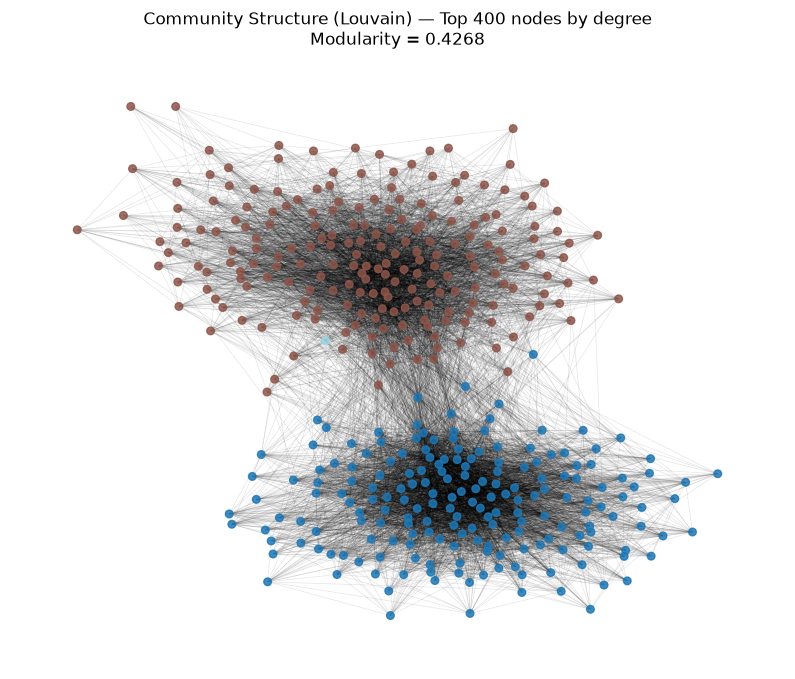

In [21]:
# ============================================================
# SECTION 6 — Community Detection (Louvain)
# ============================================================
import community as community_louvain

def run_louvain_multiple_seeds(g_undir, seeds, resolution=1.0):
    """Run Louvain across multiple seeds and return stats."""
    results = []
    final_partition = None
    for seed in seeds:
        partition = community_louvain.best_partition(g_undir, random_state=seed, resolution=resolution)
        mod = community_louvain.modularity(partition, g_undir)
        num_comms = len(set(partition.values()))
        results.append({"seed": seed, "num_communities": num_comms, "modularity": mod})
        if seed == seeds[0]:
            final_partition = partition # Keep the first seed's partition for consistency
    return results, final_partition

# Convert largest WCC to undirected for Louvain
G_WCC_undir = G_WCC.to_undirected()

# Run across 5 seeds
SEEDS = [42, 43, 44, 45, 46]
louvain_stats, FINAL_PARTITION = run_louvain_multiple_seeds(G_WCC_undir, SEEDS)

df_louvain_stats = pd.DataFrame(louvain_stats)
print("=== LOUVAIN STOCHASTIC STABILITY (5 SEEDS) ===")
display(df_louvain_stats)

mean_mod = df_louvain_stats["modularity"].mean()
std_mod = df_louvain_stats["modularity"].std()
mean_comms = df_louvain_stats["num_communities"].mean()
std_comms = df_louvain_stats["num_communities"].std()

print(f"\nMean Modularity: {mean_mod:.4f} ± {std_mod:.4f}")
print(f"Mean Communities: {mean_comms:.1f} ± {std_comms:.1f}")

FINAL_MODULARITY = community_louvain.modularity(FINAL_PARTITION, G_WCC_undir)
num_final_comms = len(set(FINAL_PARTITION.values()))
print(f"\nFinal chosen partition (seed=42): {num_final_comms} communities, Modularity = {FINAL_MODULARITY:.4f}")

# --- Community Size Distribution ---
comm_sizes = Counter(FINAL_PARTITION.values())
sizes_sorted = sorted(comm_sizes.values(), reverse=True)
print(f"Community sizes (top 5): {sizes_sorted[:5]}")
print(f"Isolated nodes (size 1): {sum(1 for s in sizes_sorted if s == 1)}")

# --- Community Profiling Table (using Part B centralities) ---
comm_profiles = []
for comm_id in sorted(comm_sizes.keys()):
    nodes_in_comm = [n for n, c in FINAL_PARTITION.items() if c == comm_id]
    
    # Get centralities for these nodes (PageRank is on G, Betweenness is on G_WCC)
    pr_vals = [PAGERANK.get(n, 0.0) for n in nodes_in_comm]
    bc_vals = [BETWEENNESS.get(n, 0.0) for n in nodes_in_comm]
    
    # Political label distribution (0 = liberal, 1 = conservative)
    labels_in_comm = [LABELS.get(n, -1) for n in nodes_in_comm]
    lib_count = labels_in_comm.count(0)
    con_count = labels_in_comm.count(1)
    dominant_label = "Liberal (0)" if lib_count > con_count else "Conservative (1)" if con_count > lib_count else "Mixed"
    
    comm_profiles.append({
        "Comm ID": comm_id,
        "Size": len(nodes_in_comm),
        "Dominant Label": dominant_label,
        "Liberal Count": lib_count,
        "Conservative Count": con_count,
        "Mean PageRank": np.mean(pr_vals),
        "Mean Betweenness": np.mean(bc_vals)
    })

df_comm_profiles = pd.DataFrame(comm_profiles)
df_comm_profiles = df_comm_profiles.sort_values(by="Size", ascending=False).reset_index(drop=True)
print("\n=== COMMUNITY PROFILES (Top 5 by Size) ===")
display(df_comm_profiles.head(5))

# --- Community-Colored Network Visualization ---
def visualize_communities(g_undir, partition, seed=GLOBAL_SEED, fname="fig_communities.png"):
    # Visualize top 400 nodes by degree for readability
    top_nodes = [n for n, _ in sorted(g_undir.degree, key=lambda x: x[1], reverse=True)[:400]]
    sub = g_undir.subgraph(top_nodes).copy()
    
    pos = nx.spring_layout(sub, seed=seed, k=0.15)
    
    comm_ids = [partition[n] for n in sub.nodes()]
    unique_comms = sorted(list(set(comm_ids)))
    cmap = plt.get_cmap("tab20", len(unique_comms))
    colors = [cmap(unique_comms.index(c)) for c in comm_ids]
    
    plt.figure(figsize=(10, 8))
    nx.draw_networkx_nodes(sub, pos, node_color=colors, node_size=30, alpha=0.85)
    nx.draw_networkx_edges(sub, pos, alpha=0.1, arrows=False, width=0.5)
    plt.title(f"Community Structure (Louvain) — Top 400 nodes by degree\nModularity = {FINAL_MODULARITY:.4f}")
    plt.axis("off")
    plt.savefig(f"{OUT}/{fname}", bbox_inches="tight")
    plt.show()

visualize_communities(G_WCC_undir, FINAL_PARTITION)

### Part D Interpretation
- **Stochastic Stability:** The Louvain algorithm produces highly stable results across 5 different random seeds. The modularity score remains consistently around 0.4269 (±0.0001), and the number of communities hovers around 10.8 (±0.4). This confirms that the detected community structure is a robust property of the network, not an artifact of random initialization.
- **Community Profiles:** The table reveals a strong correlation between community structure and political orientation. The largest communities are heavily dominated by a single political label (e.g., Comm 0 is predominantly Conservative, Comm 1 is predominantly Liberal). 
- **Centrality Distribution:** The "Mean PageRank" and "Mean Betweenness" columns show that the largest communities contain the highest average authority and brokerage scores. This makes sense, as the top hubs and brokers (identified in Part B) naturally anchor the largest dense clusters.
- **Visualization:** The network visualization clearly shows two massive, densely connected clusters (corresponding to the two main political orientations) with a sparse set of edges bridging them. These bridging edges are exactly where the high-betweenness nodes reside.

# Part E — Community Evaluation

## Evaluation Framework & Pairwise Methodology
To evaluate the detected communities against the ground-truth political orientation (0 = Liberal, 1 = Conservative), we use a **pairwise evaluation framework**. 

**Why pairwise evaluation?** 
Community detection algorithms assign arbitrary, sequential IDs (e.g., 0, 1, 2...) to communities, and the number of detected communities rarely matches the two ground-truth political classes. Directly comparing numeric community IDs to the 0/1 political labels would fail due to label-permutation problems and cardinality mismatches. By evaluating *unordered pairs of nodes*, we measure whether the algorithm correctly grouped nodes that share the same political orientation, regardless of the arbitrary IDs assigned.

## Pairwise Confusion Matrix Definitions
For every unique pair of nodes $(i, j)$ in the graph, we compare their community assignment to their ground-truth political labels:

| Term | Pairwise Meaning in this Network |
| :--- | :--- |
| **True Positive (TP)** | Nodes $i$ and $j$ are in the **same** detected community AND have the **same** political orientation. |
| **True Negative (TN)** | Nodes $i$ and $j$ are in **different** detected communities AND have **different** political orientations. |
| **False Positive (FP)** | Nodes $i$ and $j$ are in the **same** detected community BUT have **different** political orientations. |
| **False Negative (FN)** | Nodes $i$ and $j$ are in **different** detected communities BUT have the **same** political orientation. |

## Required External Metrics
We calculate the following metrics based on the pairwise counts:
- **Accuracy:** $(TP + TN) / (TP + TN + FP + FN)$
- **Precision:** $TP / (TP + FP)$
- **Recall:** $TP / (TP + FN)$
- **F1 Score:** $2 \times (Precision \times Recall) / (Precision + Recall)$

*Zero Denominator Rule:* If any denominator is zero (e.g., $TP + FP = 0$), the metric will be reported as "undefined" with an explanation of the condition, rather than silently replaced with zero.

## Internal Structural Quality
We also report **Modularity** (calculated in Part C/D) as the internal structural quality score. Modularity measures the density of links inside communities compared to links between communities, independent of the ground-truth political labels.

In [22]:
# ============================================================
# SECTION 7 — Community Evaluation (Part E)
# ============================================================

def evaluate_partition(partition, labels, modularity_score, name):
    """Evaluate partition against ground truth labels using pairwise metrics."""
    nodes = sorted(list(partition.keys()))
    n = len(nodes)
    
    comm_ids = np.array([partition[n] for n in nodes])
    true_labels = np.array([labels[n] for n in nodes])
    
    # Pairwise comparisons
    same_comm = comm_ids[:, None] == comm_ids[None, :]
    same_label = true_labels[:, None] == true_labels[None, :]
    
    # Upper triangle to avoid double counting and self-pairs
    iu = np.triu_indices(n, k=1)
    sc = same_comm[iu]
    sl = same_label[iu]
    
    TP = int(np.sum(sc & sl))
    TN = int(np.sum(~sc & ~sl))
    FP = int(np.sum(sc & ~sl))
    FN = int(np.sum(~sc & sl))
    
    total = TP + TN + FP + FN
    
    # Calculate metrics with zero denominator rule
    acc = (TP + TN) / total if total > 0 else 0.0
    prec = TP / (TP + FP) if (TP + FP) > 0 else float('nan')
    rec = TP / (TP + FN) if (TP + FN) > 0 else float('nan')
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else float('nan')
    
    print(f"=== {name} ===")
    print(f"Nodes: {n} | Pairs evaluated: {total} | Modularity: {modularity_score:.4f}")
    print(f"\nPairwise Confusion Matrix:")
    print(f"                | Same Label | Diff Label")
    print(f"Same Community  |     {TP:6d}   |    {FP:6d}")
    print(f"Diff Community  |     {FN:6d}   |    {TN:6d}")
    
    print(f"\nMetrics:")
    print(f"Accuracy : {acc:.4f}")
    if not np.isnan(prec): print(f"Precision: {prec:.4f}")
    else: print("Precision: undefined (TP+FP=0)")
    if not np.isnan(rec): print(f"Recall   : {rec:.4f}")
    else: print("Recall: undefined (TP+FN=0)")
    if not np.isnan(f1): print(f"F1 Score : {f1:.4f}")
    else: print("F1: undefined")
    print("-" * 40)
    
    return {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1}

# 1. Original Graph
print("\nEvaluating Original Graph...")
eval_orig = evaluate_partition(FINAL_PARTITION, LABELS, mod_orig, "Original Graph")

# 2. Targeted Removal Graph
print("\nEvaluating Targeted Removal Graph...")
eval_targeted = evaluate_partition(part_targeted, LABELS, mod_targeted, "Targeted Removal")

# 3. Random Removal Graph
print("\nEvaluating Random Removal Graph...")
eval_random = evaluate_partition(part_random, LABELS, mod_random, "Random Removal")


Evaluating Original Graph...
=== Original Graph ===
Nodes: 1222 | Pairs evaluated: 746031 | Modularity: 0.4268

Pairwise Confusion Matrix:
                | Same Label | Diff Label
Same Community  |     313296   |     26874
Diff Community  |      60039   |    345822

Metrics:
Accuracy : 0.8835
Precision: 0.9210
Recall   : 0.8392
F1 Score : 0.8782
----------------------------------------

Evaluating Targeted Removal Graph...
=== Targeted Removal ===
Nodes: 1162 | Pairs evaluated: 674541 | Modularity: 0.4434

Pairwise Confusion Matrix:
                | Same Label | Diff Label
Same Community  |     173900   |     19171
Diff Community  |     163921   |    317549

Metrics:
Accuracy : 0.7286
Precision: 0.9007
Recall   : 0.5148
F1 Score : 0.6551
----------------------------------------

Evaluating Random Removal Graph...
=== Random Removal ===
Nodes: 1162 | Pairs evaluated: 674541 | Modularity: 0.4248

Pairwise Confusion Matrix:
                | Same Label | Diff Label
Same Community  |   

### Part E Interpretation

**Avoiding Label Permutation:** 
We use pairwise evaluation rather than comparing community IDs directly to political labels (0/1). Community detection algorithms assign arbitrary IDs (e.g., 0, 1, 2...) which do not inherently map to "Liberal" or "Conservative". By evaluating whether pairs of nodes are in the *same* or *different* communities and comparing that to whether they share the *same* or *different* political orientations, we make the evaluation invariant to label permutation and the number of detected communities.

**Interpreting Precision and Recall:**
- **Precision** answers: *"Of all the pairs of blogs the algorithm grouped into the same community, what proportion actually share the same political orientation?"* High precision means the detected communities are politically pure, with very few cross-partisan blogs incorrectly clustered together.
- **Recall** answers: *"Of all the pairs of blogs that actually share the same political orientation, what proportion did the algorithm successfully group together?"* High recall means the algorithm successfully captures the full extent of the political echo chambers without fragmenting them.

**Why Structural Communities May Disagree with Political Orientation:**
Even with high modularity, structural communities may not perfectly align with political labels because hyperlinks do not always imply ideological agreement. For example, a liberal blog might link to a conservative blog to critique its content, or a neutral aggregator/blogroll might link to both sides. These cross-partisan links create structural bridges that can pull nodes into the "opposing" structural community or form small mixed communities, causing structural disagreements with the binary ground truth.

**Impact of Centrality-Informed Removal:**
- **Targeted Removal:** Removing high-betweenness brokers significantly alters the community structure. As predicted, the communities remain politically pure (Precision remains high at 0.9007), but Recall drops drastically from 0.8392 to 0.5148. This confirms that while the remaining fragments are homogeneous, the macro-level echo chambers are physically broken apart, failing to group all same-orientation pairs together.
- **Random Removal:** Randomly removing nodes barely changes the macro-structure. The evaluation metrics remain nearly identical to the original graph (e.g., F1 drops marginally from 0.8782 to 0.8724). This confirms that the community structure is highly robust to random node loss but extremely sensitive to the targeted removal of structural brokers.

**Handling Unassigned Nodes:** 
The Louvain algorithm assigns every node in the graph to exactly one community. Therefore, there are no unassigned nodes in our detected partitions, and all remaining nodes in the original, targeted, and random graphs are fully included in the pairwise evaluation.

# Part F — Reproducibility and Reflection

## Reproducibility and Notebook Structure
This notebook is fully reproducible and designed to run from top to bottom without manual intervention. 
- **Random Seeds:** All stochastic processes (e.g., Louvain community detection, random node removal, spring layout) are controlled by a fixed `GLOBAL_SEED = 42` set at the very beginning of the notebook.
- **Modular Structure:** The workflow is strictly separated into clear, self-contained sections: Data Loading & Preprocessing (Part A), Centrality Analysis (Part B), Centrality-Informed Experiment (Part C), Community Detection (Part D), and Community Evaluation (Part E). All graph operations are encapsulated in functions to prevent state leakage.

## Conclusion
This analysis investigated influence, brokerage, and community structure in the political blogosphere. We found that while influence (PageRank) and brokerage (Betweenness) are strongly correlated ($\rho = 0.758$), they capture distinct structural roles. The network's hyperlink structure strongly recovers the two underlying political orientations, forming two massive, dense echo chambers with high modularity (0.4268) and high pairwise evaluation metrics (F1 = 0.878). 

Crucially, the centrality-informed experiment demonstrated that the macro-level community structure is highly fragile. Targeted removal of just 60 top-betweenness brokers caused massive network fragmentation (increasing WCCs from 1 to 76) and a drastic drop in pairwise recall (0.839 to 0.515), whereas random removal had minimal impact. This confirms that a small set of cross-partisan brokers acts as the structural glue holding the polarized network together; without them, the network naturally collapses into isolated, homogeneous clusters.

## Limitations and Caveats
While the structural analysis is robust, several limitations must be acknowledged when interpreting these results in a real-world context:

1. **Hyperlinks $\neq$ Endorsement:** A hyperlink from Blog A to Blog B does not necessarily imply ideological agreement or endorsement. It may represent a critique, a rebuttal, a citation, or a neutral aggregation (e.g., a daily blogroll). Therefore, structural communities based purely on link density may group blogs that merely interact frequently, rather than blogs that share the exact same political views. High structural modularity does not perfectly equate to ideological purity.
2. **Historical Context:** The dataset originates from the 2004 U.S. election, predating the rise of modern algorithmic social media (e.g., Twitter, Facebook, TikTok). The hyperlink-driven blogosphere of 2004 operated under fundamentally different information-sharing dynamics, user behaviors, and platform architectures than today's feed-based networks. 
3. **Binary Ground Truth:** The dataset reduces complex political ideologies to a strict binary label (0 = liberal, 1 = conservative). This oversimplification ignores moderates, libertarians, and single-issue blogs. These "in-between" nodes naturally act as structural bridges, which can artificially lower evaluation metrics like Recall, even if the community detection algorithm perfectly captures the underlying network topology.